### Example 2 - Matrix Approach

The initial condition is

$$
u(x,0)=e^{-(x+1)},
$$

- and the Dirichlet boundary rows are replaced by the Neumann conditions
$$
u_x(-1,t)=-1,
\qquad
u_x(1,t)=-e^{-2}.
$$

Because the Chebyshev differentiation matrix satisfies
$$
DU\approx u_x,
$$

its first and last rows can be used directly to enforce the two
derivative boundary conditions.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from IPython.display import display, Markdown

In [13]:
def cheb(N):

    """Chebyshev-Gauss-Lobatto points and first derivative matrix."""

    if N == 0:
        return np.array([[0.0]]), np.array([1.0])

    # Chebyshev-Gauss-Lobatto points
    x = np.cos(np.pi * np.arange(N + 1) / N)

    # Coefficients
    c = np.ones(N + 1)
    c[0] = 2.0
    c[-1] = 2.0
    c = ( c * (-1.0) ** np.arange(N + 1))

    # Matrix containing x values
    X = np.tile(x.reshape(N + 1, 1),(1, N + 1))
    dX = X - X.T

    # Differentiation matrix
    D = (
        (c.reshape(N + 1, 1) / c.reshape(1, N + 1))
        /(dX + np.eye(N + 1))
    )

    # Diagonal entries
    D = D - np.diag(np.sum(D, axis=1))

    return D, x

### Check the Differentiation Matrix

In [14]:
D, x = cheb(10)
f = x**2
numerical_derivative = D @ f
exact_derivative = 2*x
error = np.max(np.abs( numerical_derivative - exact_derivative ))

print("Chebyshev derivative test error =",error)

Chebyshev derivative test error = 3.552713678800501e-15


### Reaction Function and Its Derivative

In [15]:
def reaction(u, cs, a):
    """F(u) = cs*u*(1-u)*(u-a)."""
    return cs * u * (1 - u) * (u - a)


def reaction_derivative(u, cs, a):
    """F'(u) = cs*(-3u^2 + 2(1+a)u - a)."""
    return cs * (-3*u**2 + 2*(1 + a)*u - a)

In [16]:
def solve_example2_cheb_cn(
    N=20,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    dt=0.001,
    tol=1e-10,
    max_iter=30
):
    # ---------------------------------------------------------
    # Chebyshev grid and differentiation matrices
    # ---------------------------------------------------------
    D, x = cheb(N)
    D2 = D @ D
    I = np.eye(N + 1)

    # ---------------------------------------------------------
    # Example 2 initial condition
    #
    # u(x,0) = exp(-(x+1))
    # ---------------------------------------------------------
    U = np.exp(-(x + 1))

    # The Chebyshev points are ordered:
    # x[0]  =  1
    # x[-1] = -1
    #
    # Example 2 Neumann conditions:
    # u_x( 1,t) = -exp(-2)
    # u_x(-1,t) = -1
    right_derivative = -np.exp(-2)
    left_derivative = -1.0

    # ---------------------------------------------------------
    # Time discretization
    # ---------------------------------------------------------
    Nt = int(np.ceil(t_final / dt))
    dt = t_final / Nt

    A_diffusion = I - 0.5 * dt * cd * D2
    B_diffusion = I + 0.5 * dt * cd * D2

    # Use an even N for the main midpoint graph so x=0 is a node.
    mid_index = np.argmin(np.abs(x))

    time_values = [0.0]
    midpoint_values = [U[mid_index]]

    maximum_iterations_used = 0

    # =========================================================
    # TIME LOOP
    # =========================================================
    for n in range(Nt):

        U_old = U.copy()

        # Initial guess for the new time level
        U_iter = U_old.copy()

        converged = False

        # =====================================================
        # QUASILINEARIZATION LOOP
        # =====================================================
        for r in range(max_iter):

            F_iter = reaction(U_iter, cs, a)
            Fprime_iter = reaction_derivative(U_iter, cs, a)

            # B_r = F(U_r) - F'(U_r) U_r
            B_r = F_iter - Fprime_iter * U_iter

            # Left-hand matrix from quasilinearized CN
            A = (
                A_diffusion
                - 0.5 * dt * np.diag(Fprime_iter)
            )

            # Right-hand side
            rhs = (
                B_diffusion @ U_old
                + 0.5 * dt
                * (
                    reaction(U_old, cs, a)
                    + B_r
                )
            )

            # -------------------------------------------------
            # EXAMPLE 2: NEUMANN BOUNDARY CONDITIONS
            #
            # Since D @ U approximates u_x:
            #
            # row 0 corresponds to x = 1
            # row -1 corresponds to x = -1
            # -------------------------------------------------

            # u_x(1,t) = -exp(-2)
            A[0, :] = D[0, :]
            rhs[0] = right_derivative

            # u_x(-1,t) = -1
            A[-1, :] = D[-1, :]
            rhs[-1] = left_derivative

            # Solve the linear system
            U_next = np.linalg.solve(A, rhs)

            iteration_error = np.max(
                np.abs(U_next - U_iter)
            )

            U_iter = U_next

            if iteration_error < tol:
                converged = True
                break

        if not converged:
            raise RuntimeError(
                f"Quasilinearization did not converge at time step {n + 1}."
            )

        maximum_iterations_used = max(
            maximum_iterations_used,
            r + 1
        )

        U = U_iter

        time_values.append((n + 1) * dt)
        midpoint_values.append(U[mid_index])

    return (
        x,
        U,
        np.array(time_values),
        np.array(midpoint_values),
        dt,
        maximum_iterations_used
    )


In [17]:
x_main, u_main, t_main, midpoint_main, dt_used, max_iterations = (
    solve_example2_cheb_cn(
        N=20,
        cd=1.0,
        cs=50.0,
        a=0.5,
        t_final=0.5,
        dt=0.001
    )
)

mask_01 = t_main <= 0.1 + 1e-12

print("dt =", dt_used)
print("Starting midpoint =", midpoint_main[0])
print("Midpoint at t = 0.1 =", midpoint_main[mask_01][-1])
print("Final midpoint at t = 0.5 =", midpoint_main[-1])
print("Maximum nonlinear iterations used =", max_iterations)
print("Minimum u at t = 0.5 =", np.min(u_main))
print("Maximum u at t = 0.5 =", np.max(u_main))
print("Contains NaN =", np.isnan(u_main).any())
print("Contains infinity =", np.isinf(u_main).any())


dt = 0.001
Starting midpoint = 0.36787944117144233
Midpoint at t = 0.1 = 0.27387843911497345
Final midpoint at t = 0.5 = 0.29006558154027634
Maximum nonlinear iterations used = 3
Minimum u at t = 0.5 = -0.02171271516074403
Maximum u at t = 0.5 = 1.1530871237163045
Contains NaN = False
Contains infinity = False


## Midpoint Graph $u(0,t)$ 


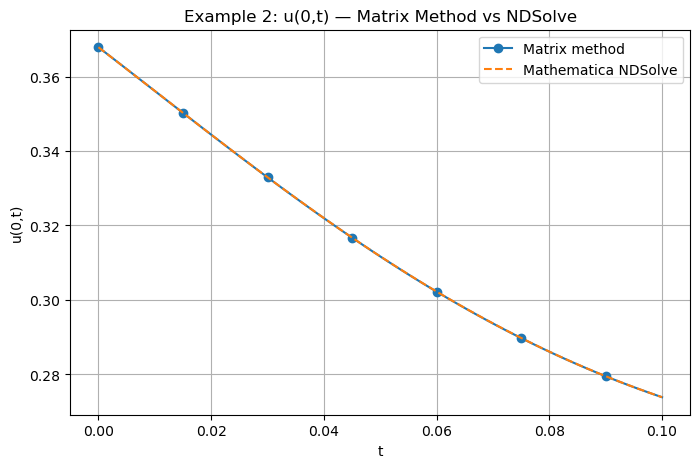

In [18]:


# Load Mathematica midpoint reference
midpoint_ref = pd.read_csv(
    "example2_ndsolve_midpoint.csv"
)

t_nd = midpoint_ref["t"].to_numpy(dtype=float)
u_nd = midpoint_ref["u"].to_numpy(dtype=float)

# Only use t <= 0.1 from the numerical matrix solution
mask = t_main <= 0.1 + 1e-12

plt.figure(figsize=(8, 5))

plt.plot(
    t_main[mask],
    midpoint_main[mask],
    marker="o",
    markevery=15,
    label="Matrix method"
)

plt.plot(
    t_nd,
    u_nd,
    linestyle="--",
    label="Mathematica NDSolve"
)

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 2: u(0,t) — Matrix Method vs NDSolve")
plt.grid(True)
plt.legend()

plt.show()

##  Mathematica `NDSolve` Reference




In [9]:
ndsolve_data = pd.read_csv("example2_ndsolve_t05.csv")

required_columns = {"x", "u"}

if not required_columns.issubset(ndsolve_data.columns):
    raise ValueError(
        "The CSV must contain columns named 'x' and 'u'. "
        f"Found columns: {list(ndsolve_data.columns)}"
    )

x_nd = ndsolve_data["x"].to_numpy(dtype=float)
u_nd = ndsolve_data["u"].to_numpy(dtype=float)

sort_idx = np.argsort(x_nd)
x_nd = x_nd[sort_idx]
u_nd = u_nd[sort_idx]

if np.isnan(x_nd).any() or np.isnan(u_nd).any():
    raise ValueError(
        "NaN values were found in the NDSolve reference."
    )

if not np.isfinite(x_nd).all() or not np.isfinite(u_nd).all():
    raise ValueError(
        "Non-finite values were found in the NDSolve reference."
    )

ndsolve_interp = CubicSpline(
    x_nd,
    u_nd
)

print("NDSolve reference loaded successfully.")
print("Number of reference points =", len(x_nd))
print("x-range =", (x_nd[0], x_nd[-1]))
print("Endpoint values =", (u_nd[0], u_nd[-1]))


NDSolve reference loaded successfully.
Number of reference points = 2001
x-range = (np.float64(-1.0), np.float64(1.0))
Endpoint values = (np.float64(1.1550634300677882), np.float64(-0.0217589675328223))


## Maximum Absolute Error 


In [10]:
N_values = [5, 10, 15, 20, 25, 30]

matrix_errors = []

print("N        Maximum absolute error vs NDSolve")
print("------------------------------------------")

for N in N_values:

    # Solve Example 2 using the matrix/Chebyshev method
    x_test, u_test, _, _, _, _ = (
        solve_example2_cheb_cn(
            N=N,
            cd=1.0,
            cs=50.0,
            a=0.5,
            t_final=0.5,
            dt=0.001
        )
    )

    # Evaluate Mathematica NDSolve at the same Chebyshev points
    u_nd_at_test = ndsolve_interp(x_test)

    # Pointwise absolute error
    absolute_error = np.abs(
        u_test - u_nd_at_test
    )

    # Maximum absolute error
    max_error = np.max(
        absolute_error
    )

    matrix_errors.append(max_error)

    # Print ordinary decimals
    print(
        f"{N:<8} {max_error:.10f}"
    )


N        Maximum absolute error vs NDSolve
------------------------------------------
5        0.1769622423
10       0.0044818985
15       0.0021960201
20       0.0019763064
25       0.0019670952
30       0.0019672187


## Check the Neumann Boundary Conditions




In [11]:
D_check, x_check = cheb(20)

# x[0] = 1
right_slope = D_check[0, :] @ u_main

# x[-1] = -1
left_slope = D_check[-1, :] @ u_main

print("Left boundary slope  =", left_slope)
print("Expected left slope  =", -1.0)

print("Right boundary slope =", right_slope)
print("Expected right slope =", -np.exp(-2))


Left boundary slope  = -1.0000000000000284
Expected left slope  = -1.0
Right boundary slope = -0.1353352832366128
Expected right slope = -0.1353352832366127


## Discussion of Matrix-Method Results

For Example 2, the matrix method was compared with the Mathematica
`NDSolve` solution at

$$
t=0.5.
$$

The maximum absolute errors were:

| $N$ | Maximum Absolute Error |
|---:|---:|
| 5  | 0.1769622423 |
| 10 | 0.0044818985 |
| 15 | 0.0021960201 |
| 20 | 0.0019763064 |
| 25 | 0.0019670952 |
| 30 | 0.0019672187 |

The first thing that stands out is the very large drop in error between

$$
N=5
$$

and

$$
N=10.
$$

The error falls from

$$
0.1769622423
$$

to only

$$
0.0044818985.
$$

This shows how quickly the Chebyshev collocation method can improve when
more collocation points are added.

The error continues to decrease at

$$
N=15
$$

and

$$
N=20,
$$

reaching

$$
0.0019763064.
$$

After this point, however, the improvement becomes very small.

At

$$
N=25,
$$

the error is

$$
0.0019670952,
$$

and at

$$
N=30
$$

it is

$$
0.0019672187.
$$

So from about $N=20$ onward, the error has almost reached a plateau.

This does not mean that the method has become unstable. Instead, it
suggests that increasing the spatial resolution further is no longer
making a noticeable difference to the comparison with `NDSolve`.

At this stage, other parts of the numerical calculation, such as the
time discretization, the nonlinear iteration, and the numerical
reference itself, can become more important than the spatial error.

Overall, the matrix approach gives a very strong improvement as the
Chebyshev resolution is increased from $N=5$ to $N=20$. After that, the
solution changes very little, with the maximum error remaining close to

$$
0.00197.
$$